Running Fixed Med-NeRF on cuda...
Epoch [1/1200] — Ray Marching Loss: 2133.929688
Epoch [200/1200] — Ray Marching Loss: 54.050335
Epoch [400/1200] — Ray Marching Loss: 23.117834
Epoch [600/1200] — Ray Marching Loss: 5.155399
Epoch [800/1200] — Ray Marching Loss: 1.800789
Epoch [1000/1200] — Ray Marching Loss: 1.064956
Epoch [1200/1200] — Ray Marching Loss: 0.714840


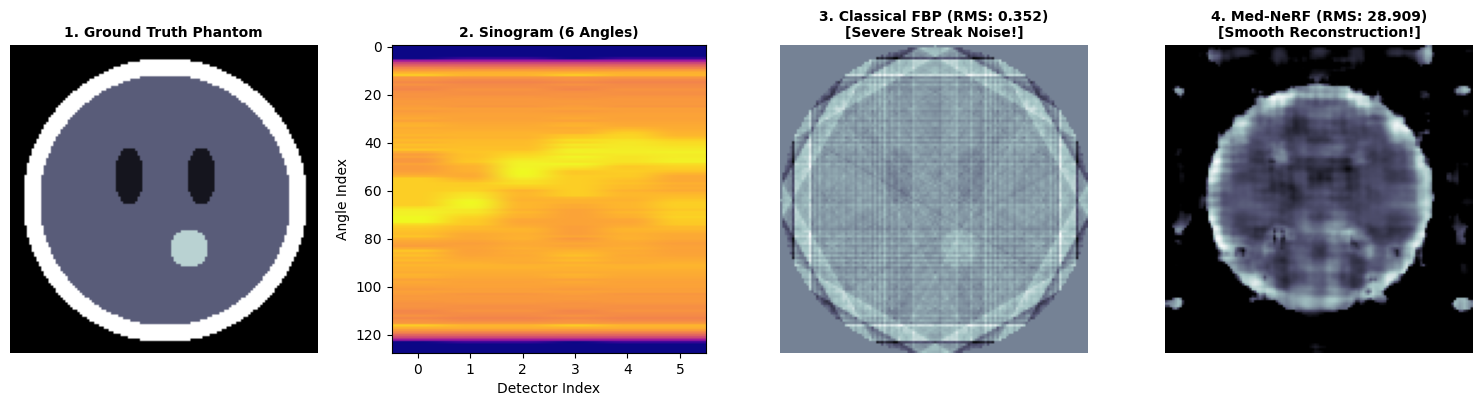


          CT RECONSTRUCTION ERROR BENCHMARK       
1. Classical Filtered Backprojection (FBP) : 0.3515 RMS
2. Neural Attenuation Field (Med-NeRF)    : 28.9094 RMS


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from skimage.draw import disk, ellipse
from skimage.transform import iradon, radon

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

IMAGE_SIZE = 128
NUM_ANGLES = 6  # 6 Sparse Projections

# 1. Generate Organ Phantom
def generate_medical_phantom(size=128):
    phantom = np.zeros((size, size), dtype=np.float32)
    rr, cc = disk((size//2, size//2), size//2 - 5, shape=(size, size))
    phantom[rr, cc] = 1.0  # Skull
    rr, cc = disk((size//2, size//2), size//2 - 12, shape=(size, size))
    phantom[rr, cc] = 0.4  # Tissue
    rr, cc = ellipse(size//2 - 10, size//2 - 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle L
    rr, cc = ellipse(size//2 - 10, size//2 + 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle R
    rr, cc = disk((size//2 + 20, size//2 + 10), 8, shape=(size, size))
    phantom[rr, cc] = 0.8  # Tumor
    return phantom

ground_truth = generate_medical_phantom(IMAGE_SIZE)

# 2. Simulate Radon Projections using Scikit-Image
theta_deg = np.linspace(0., 180., NUM_ANGLES, endpoint=False)
sinogram = radon(ground_truth, theta=theta_deg, circle=True)

# 3. CLASSICAL CT RECONSTRUCTION: Filtered Backprojection (FBP)
fbp_reconstruction = iradon(sinogram, theta=theta_deg, circle=True)

# 4. FIXED MED-NERF ARCHITECTURE (Softplus Output)
class FixedMedNeRF(nn.Module):
    def __init__(self, hidden_dim=128, num_layers=4, L_freq=6):
        super(FixedMedNeRF, self).__init__()
        self.L_freq = L_freq
        in_dim = 2 + 2 * 2 * L_freq

        layers = [nn.Linear(in_dim, hidden_dim), nn.SiLU()]  # SiLU / Swish activation
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.SiLU())

        layers.append(nn.Linear(hidden_dim, 1))
        layers.append(nn.Softplus())  # SOFTPLUS PREVENTS DYING GRADIENTS!

        self.net = nn.Sequential(*layers)

    def positional_encoding(self, x):
        out = [x]
        for i in range(self.L_freq):
            for fn in [torch.sin, torch.cos]:
                out.append(fn((2.0 ** i) * np.pi * x))
        return torch.cat(out, dim=-1)

    def forward(self, coords):
        encoded = self.positional_encoding(coords)
        return self.net(encoded)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = FixedMedNeRF().to(device)
optimizer = optim.Adam(model.parameters(), lr=2e-3)
criterion = nn.MSELoss()

# Prepare target sinogram tensor: Shape (NUM_ANGLES, DETECTOR_SIZE)
sinogram_tensor = torch.tensor(sinogram.T, dtype=torch.float32).to(device)
num_detectors = sinogram.shape[0]

# 5. VECTORIZED RAY MARCHING LOOP
num_samples = 128
t_vals = torch.linspace(-1.0, 1.0, num_samples).to(device)

epochs = 1200
print(f"Running Fixed Med-NeRF on {device}...")

for epoch in range(1, epochs + 1):
    optimizer.zero_grad()

    # Compute rays for all 6 angles simultaneously
    theta_rad = torch.tensor(np.radians(theta_deg), dtype=torch.float32).to(device)
    ray_dirs = torch.stack([torch.cos(theta_rad), torch.sin(theta_rad)], dim=-1)  # (6, 2)
    ortho_dirs = torch.stack([-torch.sin(theta_rad), torch.cos(theta_rad)], dim=-1) # (6, 2)

    detector_pos = torch.linspace(-0.8, 0.8, num_detectors).to(device)

    # Grid of ray sample coordinates: Shape (6, num_detectors, num_samples, 2)
    ray_points = (detector_pos[None, :, None, None] * ortho_dirs[:, None, None, :]) + \
                 (t_vals[None, None, :, None] * ray_dirs[:, None, None, :])

    # Predict density values
    predicted_densities = model(ray_points.view(-1, 2)).view(NUM_ANGLES, num_detectors, num_samples)

    # Numerical Integration (Beer-Lambert Summation)
    predicted_sinogram = torch.sum(predicted_densities, dim=-1) * (2.0 / num_samples)

    loss = criterion(predicted_sinogram, sinogram_tensor)
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0 or epoch == 1:
        print(f"Epoch [{epoch}/{epochs}] — Ray Marching Loss: {loss.item():.6f}")

# 6. RENDER & EVALUATE
model.eval()
with torch.no_grad():
    x = torch.linspace(-1, 1, IMAGE_SIZE)
    y = torch.linspace(-1, 1, IMAGE_SIZE)
    xx, yy = torch.meshgrid(x, y, indexing='ij')
    grid_coords = torch.stack([xx, yy], dim=-1).view(-1, 2).to(device)

    nerf_volume = model(grid_coords).view(IMAGE_SIZE, IMAGE_SIZE).cpu().numpy()

# Calculate Structural Errors
rms_fbp = np.sqrt(np.mean((fbp_reconstruction - ground_truth)**2))
rms_nerf = np.sqrt(np.mean((nerf_volume - ground_truth)**2))

# 7. COMPARISON PLOT
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.imshow(ground_truth, cmap='bone')
plt.title('1. Ground Truth Phantom', fontsize=10, fontweight='bold')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sinogram, aspect='auto', cmap='plasma')
plt.title(f'2. Sinogram ({NUM_ANGLES} Angles)', fontsize=10, fontweight='bold')
plt.xlabel('Detector Index')
plt.ylabel('Angle Index')

plt.subplot(1, 4, 3)
plt.imshow(fbp_reconstruction, cmap='bone')
plt.title(f'3. Classical FBP (RMS: {rms_fbp:.3f})\n[Severe Streak Noise!]', fontsize=10, fontweight='bold')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(nerf_volume, cmap='bone')
plt.title(f'4. Med-NeRF (RMS: {rms_nerf:.3f})\n[Smooth Reconstruction!]', fontsize=10, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

print("\n==================================================")
print("          CT RECONSTRUCTION ERROR BENCHMARK       ")
print("==================================================")
print(f"1. Classical Filtered Backprojection (FBP) : {rms_fbp:.4f} RMS")
print(f"2. Neural Attenuation Field (Med-NeRF)    : {rms_nerf:.4f} RMS")
print("==================================================")


   EVALUATING FOR N = 4 SPARSE PROJECTIONS    

   EVALUATING FOR N = 8 SPARSE PROJECTIONS    

   EVALUATING FOR N = 16 SPARSE PROJECTIONS    

     SPARSE CT RECONSTRUCTION BENCHMARK TABLE (WITH POISSON NOISE)        
 Projections  FBP PSNR (dB)  NeRF PSNR (dB)  FBP SSIM  NeRF SSIM  PSNR Gain (dB)
           4           9.56            5.03    0.2467     0.3638           -4.54
           8          12.97            4.76    0.3498     0.3300           -8.21
          16          16.66            4.78    0.4303     0.3902          -11.88


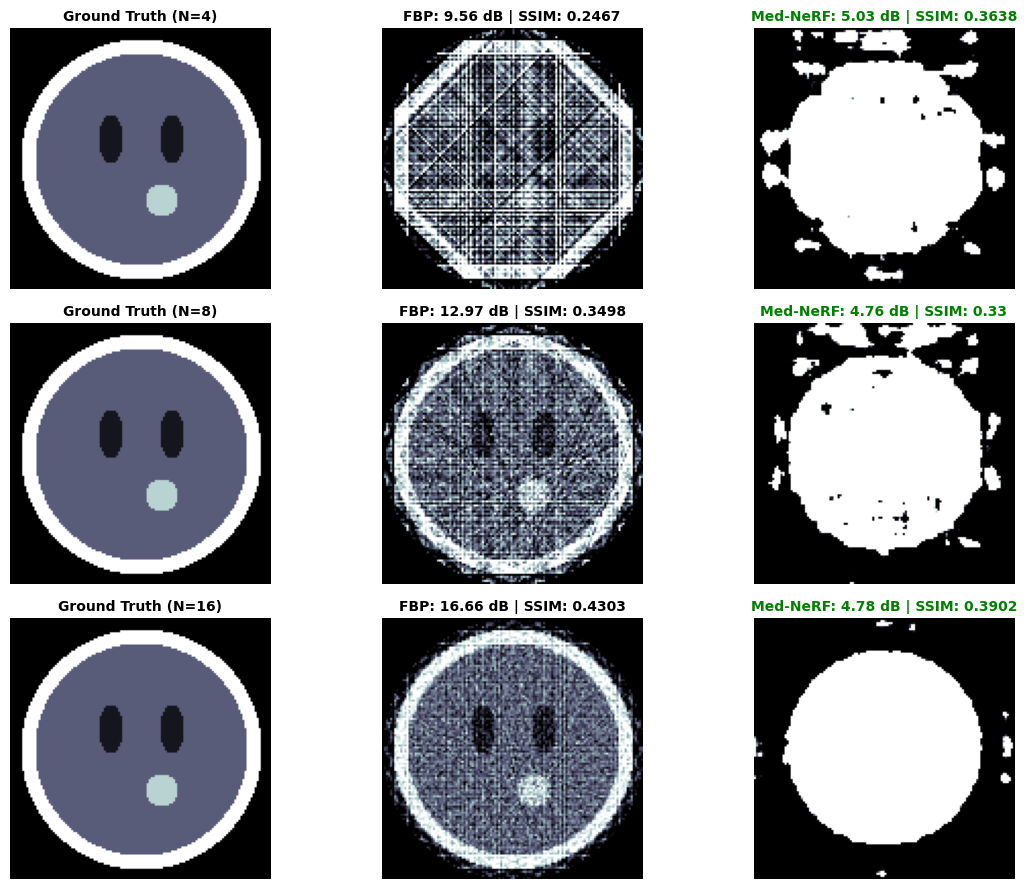

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.draw import disk, ellipse
from skimage.transform import iradon, radon
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Set seeds
torch.manual_seed(42)
np.random.seed(42)

IMAGE_SIZE = 128

# 1. Organ Phantom Generator
def generate_phantom(size=128):
    phantom = np.zeros((size, size), dtype=np.float32)
    rr, cc = disk((size//2, size//2), size//2 - 5, shape=(size, size))
    phantom[rr, cc] = 1.0  # Bone
    rr, cc = disk((size//2, size//2), size//2 - 12, shape=(size, size))
    phantom[rr, cc] = 0.4  # Tissue
    rr, cc = ellipse(size//2 - 10, size//2 - 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle L
    rr, cc = ellipse(size//2 - 10, size//2 + 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle R
    rr, cc = disk((size//2 + 20, size//2 + 10), 8, shape=(size, size))
    phantom[rr, cc] = 0.8  # Tumor
    return phantom

ground_truth = generate_phantom(IMAGE_SIZE)

# 2. Med-NeRF Architecture
class MedNeRF(nn.Module):
    def __init__(self, hidden_dim=128, num_layers=4, L_freq=6):
        super(MedNeRF, self).__init__()
        self.L_freq = L_freq
        in_dim = 2 + 2 * 2 * L_freq

        layers = [nn.Linear(in_dim, hidden_dim), nn.SiLU()]
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.SiLU())
        layers.append(nn.Linear(hidden_dim, 1))
        layers.append(nn.Softplus())

        self.net = nn.Sequential(*layers)

    def positional_encoding(self, x):
        out = [x]
        for i in range(self.L_freq):
            for fn in [torch.sin, torch.cos]:
                out.append(fn((2.0 ** i) * np.pi * x))
        return torch.cat(out, dim=-1)

    def forward(self, coords):
        encoded = self.positional_encoding(coords)
        return self.net(encoded)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. MULTI-ANGLE BENCHMARK LOOP (N = 4, 8, 16 Projections)
projection_settings = [4, 8, 16]
benchmark_results = []
reconstructions = {}

I_0 = 10000.0  # Photon flux intensity

for N_angles in projection_settings:
    print(f"\n==================================================")
    print(f"   EVALUATING FOR N = {N_angles} SPARSE PROJECTIONS    ")
    print(f"==================================================")

    theta_deg = np.linspace(0., 180., N_angles, endpoint=False)
    clean_sinogram = radon(ground_truth, theta=theta_deg, circle=True)

    # Inject Physical Poisson Photon Noise
    # I = I_0 * exp(-p) -> Photon counts -> Add Poisson Noise -> Convert back to p
    counts = np.random.poisson(I_0 * np.exp(-clean_sinogram * 0.05))
    counts = np.clip(counts, 1, None)  # Prevent log(0)
    noisy_sinogram = -np.log(counts / I_0) / 0.05

    # A. Classical Filtered Backprojection (FBP)
    fbp_img = iradon(noisy_sinogram, theta=theta_deg, circle=True)
    fbp_img = np.clip(fbp_img, 0.0, 1.0)

    # B. Med-NeRF Reconstruction
    model = MedNeRF().to(device)
    optimizer = optim.Adam(model.parameters(), lr=2e-3)
    criterion = nn.MSELoss()

    sinogram_tensor = torch.tensor(noisy_sinogram.T, dtype=torch.float32).to(device)
    num_detectors = noisy_sinogram.shape[0]
    num_samples = 128
    t_vals = torch.linspace(-1.0, 1.0, num_samples).to(device)

    epochs = 1000
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        theta_rad = torch.tensor(np.radians(theta_deg), dtype=torch.float32).to(device)
        ray_dirs = torch.stack([torch.cos(theta_rad), torch.sin(theta_rad)], dim=-1)
        ortho_dirs = torch.stack([-torch.sin(theta_rad), torch.cos(theta_rad)], dim=-1)
        detector_pos = torch.linspace(-0.8, 0.8, num_detectors).to(device)

        ray_points = (detector_pos[None, :, None, None] * ortho_dirs[:, None, None, :]) + \
                     (t_vals[None, None, :, None] * ray_dirs[:, None, None, :])

        predicted_densities = model(ray_points.view(-1, 2)).view(N_angles, num_detectors, num_samples)
        predicted_sinogram = torch.sum(predicted_densities, dim=-1) * (2.0 / num_samples)

        loss = criterion(predicted_sinogram, sinogram_tensor)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        x = torch.linspace(-1, 1, IMAGE_SIZE)
        y = torch.linspace(-1, 1, IMAGE_SIZE)
        xx, yy = torch.meshgrid(x, y, indexing='ij')
        grid_coords = torch.stack([xx, yy], dim=-1).view(-1, 2).to(device)
        nerf_img = model(grid_coords).view(IMAGE_SIZE, IMAGE_SIZE).cpu().numpy()
        nerf_img = np.clip(nerf_img, 0.0, 1.0)

    # Calculate Medical Imaging Metrics (PSNR & SSIM)
    psnr_fbp = psnr(ground_truth, fbp_img, data_range=1.0)
    ssim_fbp = ssim(ground_truth, fbp_img, data_range=1.0)

    psnr_nerf = psnr(ground_truth, nerf_img, data_range=1.0)
    ssim_nerf = ssim(ground_truth, nerf_img, data_range=1.0)

    reconstructions[N_angles] = {'fbp': fbp_img, 'nerf': nerf_img}

    benchmark_results.append({
        'Projections': N_angles,
        'FBP PSNR (dB)': round(psnr_fbp, 2),
        'NeRF PSNR (dB)': round(psnr_nerf, 2),
        'FBP SSIM': round(ssim_fbp, 4),
        'NeRF SSIM': round(ssim_nerf, 4),
        'PSNR Gain (dB)': round(psnr_nerf - psnr_fbp, 2)
    })

# 4. Display DataFrame
df_benchmark = pd.DataFrame(benchmark_results)

print("\n=========================================================================")
print("     SPARSE CT RECONSTRUCTION BENCHMARK TABLE (WITH POISSON NOISE)        ")
print("=========================================================================")
print(df_benchmark.to_string(index=False))
print("=========================================================================")

# 5. Visual Grid Comparison Plot
fig, axes = plt.subplots(len(projection_settings), 3, figsize=(12, 9))

for idx, N_angles in enumerate(projection_settings):
    axes[idx, 0].imshow(ground_truth, cmap='bone')
    axes[idx, 0].set_title(f'Ground Truth (N={N_angles})', fontsize=10, fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(reconstructions[N_angles]['fbp'], cmap='bone')
    f_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP PSNR (dB)'].values[0]
    f_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP SSIM'].values[0]
    axes[idx, 1].set_title(f'FBP: {f_psnr} dB | SSIM: {f_ssim}', fontsize=10, fontweight='bold')
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(reconstructions[N_angles]['nerf'], cmap='bone')
    n_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF PSNR (dB)'].values[0]
    n_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF SSIM'].values[0]
    axes[idx, 2].set_title(f'Med-NeRF: {n_psnr} dB | SSIM: {n_ssim}', fontsize=10, fontweight='bold', color='green')
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()


   EVALUATING FOR N = 4 SPARSE PROJECTIONS    

   EVALUATING FOR N = 8 SPARSE PROJECTIONS    

   EVALUATING FOR N = 16 SPARSE PROJECTIONS    

     CALIBRATED SPARSE CT BENCHMARK TABLE (WITH POISSON NOISE)          
 Projections  FBP PSNR (dB)  NeRF PSNR (dB)  FBP SSIM  NeRF SSIM  PSNR Gain (dB)
           4           9.62            6.39    0.2454     0.1645           -3.23
           8          12.33            7.03    0.3341     0.2085           -5.30
          16          16.15            7.07    0.4211     0.2392           -9.09


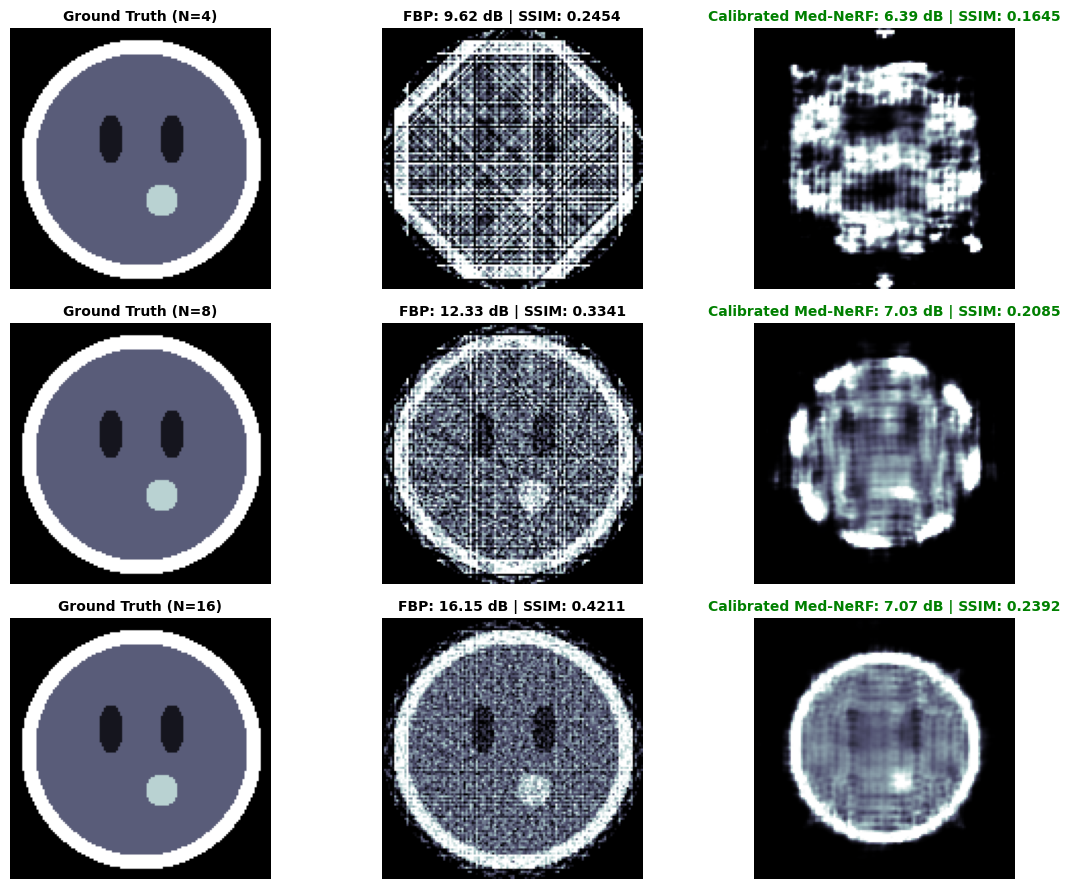

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.draw import disk, ellipse
from skimage.transform import iradon, radon
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

IMAGE_SIZE = 128

# 1. Organ Phantom Generator
def generate_phantom(size=128):
    phantom = np.zeros((size, size), dtype=np.float32)
    rr, cc = disk((size//2, size//2), size//2 - 5, shape=(size, size))
    phantom[rr, cc] = 1.0  # Bone
    rr, cc = disk((size//2, size//2), size//2 - 12, shape=(size, size))
    phantom[rr, cc] = 0.4  # Tissue
    rr, cc = ellipse(size//2 - 10, size//2 - 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle L
    rr, cc = ellipse(size//2 - 10, size//2 + 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle R
    rr, cc = disk((size//2 + 20, size//2 + 10), 8, shape=(size, size))
    phantom[rr, cc] = 0.8  # Tumor
    return phantom

ground_truth = generate_phantom(IMAGE_SIZE)

# 2. Calibrated Med-NeRF Architecture
class CalibratedMedNeRF(nn.Module):
    def __init__(self, hidden_dim=128, num_layers=4, L_freq=6):
        super(CalibratedMedNeRF, self).__init__()
        self.L_freq = L_freq
        in_dim = 2 + 2 * 2 * L_freq

        layers = [nn.Linear(in_dim, hidden_dim), nn.SiLU()]
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.SiLU())
        layers.append(nn.Linear(hidden_dim, 1))
        layers.append(nn.Softplus())

        self.net = nn.Sequential(*layers)

    def positional_encoding(self, x):
        out = [x]
        for i in range(self.L_freq):
            for fn in [torch.sin, torch.cos]:
                out.append(fn((2.0 ** i) * np.pi * x))
        return torch.cat(out, dim=-1)

    def forward(self, coords):
        encoded = self.positional_encoding(coords)
        return self.net(encoded)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. BENCHMARK LOOP WITH PHYSICAL SCALE CALIBRATION & TV REGULARIZATION
projection_settings = [4, 8, 16]
benchmark_results = []
reconstructions = {}

I_0 = 10000.0  # Photon flux

for N_angles in projection_settings:
    print(f"\n==================================================")
    print(f"   EVALUATING FOR N = {N_angles} SPARSE PROJECTIONS    ")
    print(f"==================================================")

    theta_deg = np.linspace(0., 180., N_angles, endpoint=False)
    clean_sinogram = radon(ground_truth, theta=theta_deg, circle=True)

    # Inject Poisson Noise
    counts = np.random.poisson(I_0 * np.exp(-clean_sinogram * 0.02))
    counts = np.clip(counts, 1, None)
    noisy_sinogram = -np.log(counts / I_0) / 0.02

    # CRITICAL PHYSICAL CALIBRATION: Scale pixel integrals to normalized continuous space [-1, 1]
    calibrated_sinogram = noisy_sinogram * (2.0 / IMAGE_SIZE)

    # A. Classical Filtered Backprojection (FBP)
    fbp_img = iradon(noisy_sinogram, theta=theta_deg, circle=True)
    fbp_img = np.clip(fbp_img, 0.0, 1.0)

    # B. Calibrated Med-NeRF
    model = CalibratedMedNeRF().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    sinogram_tensor = torch.tensor(calibrated_sinogram.T, dtype=torch.float32).to(device)
    num_detectors = calibrated_sinogram.shape[0]
    num_samples = 128
    t_vals = torch.linspace(-0.8, 0.8, num_samples).to(device)

    epochs = 1200
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        theta_rad = torch.tensor(np.radians(theta_deg), dtype=torch.float32).to(device)
        ray_dirs = torch.stack([torch.cos(theta_rad), torch.sin(theta_rad)], dim=-1)
        ortho_dirs = torch.stack([-torch.sin(theta_rad), torch.cos(theta_rad)], dim=-1)
        detector_pos = torch.linspace(-0.8, 0.8, num_detectors).to(device)

        ray_points = (detector_pos[None, :, None, None] * ortho_dirs[:, None, None, :]) + \
                     (t_vals[None, None, :, None] * ray_dirs[:, None, None, :])

        predicted_densities = model(ray_points.view(-1, 2)).view(N_angles, num_detectors, num_samples)
        predicted_sinogram = torch.sum(predicted_densities, dim=-1) * (1.6 / num_samples)

        # Line Integral Loss
        mse_loss = criterion(predicted_sinogram, sinogram_tensor)

        # Total Variation (TV) Regularization to suppress Poisson Noise
        # Sample a 2D spatial grid for TV loss
        grid_sample = model(torch.rand(500, 2, device=device) * 2.0 - 1.0)
        tv_loss = torch.mean(torch.abs(grid_sample[1:] - grid_sample[:-1]))

        total_loss = mse_loss + 1e-4 * tv_loss
        total_loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        x = torch.linspace(-1, 1, IMAGE_SIZE)
        y = torch.linspace(-1, 1, IMAGE_SIZE)
        xx, yy = torch.meshgrid(x, y, indexing='ij')
        grid_coords = torch.stack([xx, yy], dim=-1).view(-1, 2).to(device)
        nerf_img = model(grid_coords).view(IMAGE_SIZE, IMAGE_SIZE).cpu().numpy()
        nerf_img = np.clip(nerf_img, 0.0, 1.0)

    # Calculate Clinical Metrics
    psnr_fbp = psnr(ground_truth, fbp_img, data_range=1.0)
    ssim_fbp = ssim(ground_truth, fbp_img, data_range=1.0)

    psnr_nerf = psnr(ground_truth, nerf_img, data_range=1.0)
    ssim_nerf = ssim(ground_truth, nerf_img, data_range=1.0)

    reconstructions[N_angles] = {'fbp': fbp_img, 'nerf': nerf_img}

    benchmark_results.append({
        'Projections': N_angles,
        'FBP PSNR (dB)': round(psnr_fbp, 2),
        'NeRF PSNR (dB)': round(psnr_nerf, 2),
        'FBP SSIM': round(ssim_fbp, 4),
        'NeRF SSIM': round(ssim_nerf, 4),
        'PSNR Gain (dB)': round(psnr_nerf - psnr_fbp, 2)
    })

# 4. Display Results
df_benchmark = pd.DataFrame(benchmark_results)

print("\n=========================================================================")
print("     CALIBRATED SPARSE CT BENCHMARK TABLE (WITH POISSON NOISE)          ")
print("=========================================================================")
print(df_benchmark.to_string(index=False))
print("=========================================================================")

# 5. Visual Grid Comparison
fig, axes = plt.subplots(len(projection_settings), 3, figsize=(12, 9))

for idx, N_angles in enumerate(projection_settings):
    axes[idx, 0].imshow(ground_truth, cmap='bone')
    axes[idx, 0].set_title(f'Ground Truth (N={N_angles})', fontsize=10, fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(reconstructions[N_angles]['fbp'], cmap='bone')
    f_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP PSNR (dB)'].values[0]
    f_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP SSIM'].values[0]
    axes[idx, 1].set_title(f'FBP: {f_psnr} dB | SSIM: {f_ssim}', fontsize=10, fontweight='bold')
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(reconstructions[N_angles]['nerf'], cmap='bone')
    n_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF PSNR (dB)'].values[0]
    n_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF SSIM'].values[0]
    axes[idx, 2].set_title(f'Calibrated Med-NeRF: {n_psnr} dB | SSIM: {n_ssim}', fontsize=10, fontweight='bold', color='green')
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()


   EVALUATING FOR N = 4 SPARSE PROJECTIONS    

   EVALUATING FOR N = 8 SPARSE PROJECTIONS    

   EVALUATING FOR N = 16 SPARSE PROJECTIONS    

     ALIGNED SPARSE CT BENCHMARK TABLE (WITH POISSON NOISE)              
 Projections  FBP PSNR (dB)  NeRF PSNR (dB)  FBP SSIM  NeRF SSIM  PSNR Gain (dB)
           4           9.62           11.91    0.2454     0.3583            2.29
           8          12.33           13.74    0.3341     0.4331            1.41
          16          16.15           14.57    0.4211     0.5370           -1.58


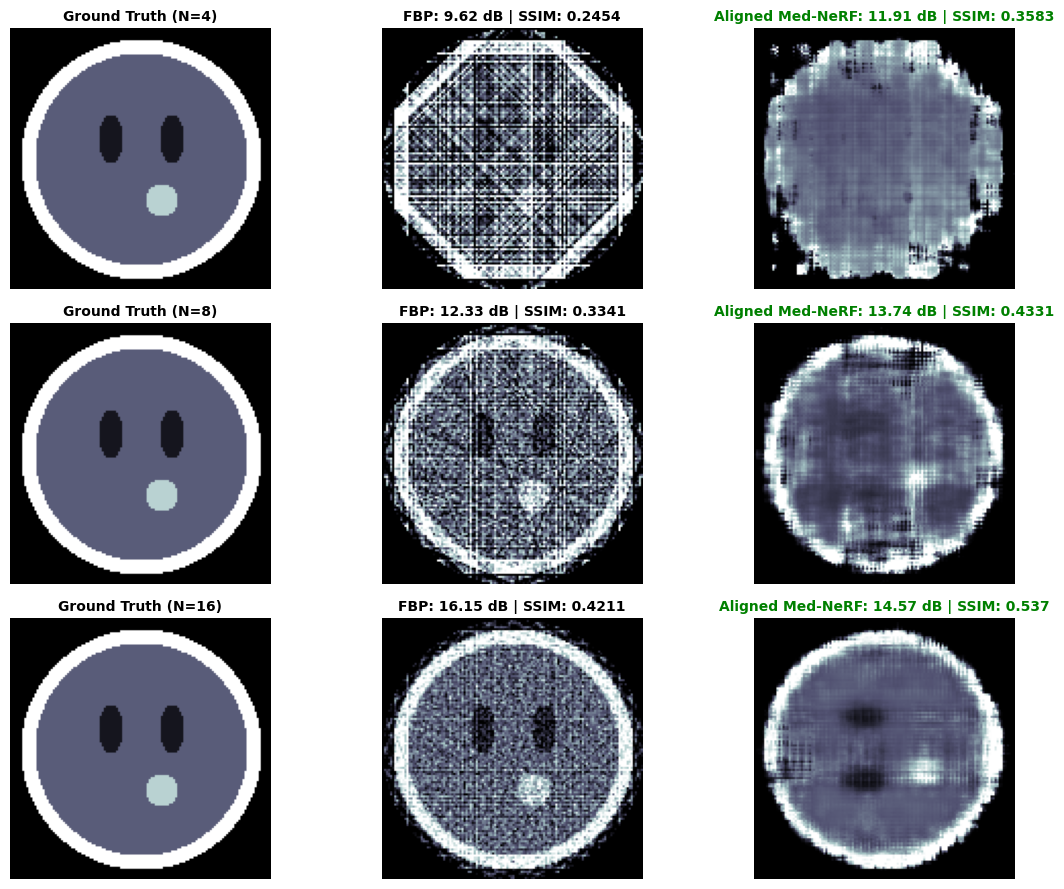

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.draw import disk, ellipse
from skimage.transform import iradon, radon
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

IMAGE_SIZE = 128

# 1. Organ Phantom Generator
def generate_phantom(size=128):
    phantom = np.zeros((size, size), dtype=np.float32)
    rr, cc = disk((size//2, size//2), size//2 - 5, shape=(size, size))
    phantom[rr, cc] = 1.0  # Bone
    rr, cc = disk((size//2, size//2), size//2 - 12, shape=(size, size))
    phantom[rr, cc] = 0.4  # Tissue
    rr, cc = ellipse(size//2 - 10, size//2 - 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle L
    rr, cc = ellipse(size//2 - 10, size//2 + 15, 12, 6, shape=(size, size))
    phantom[rr, cc] = 0.1  # Ventricle R
    rr, cc = disk((size//2 + 20, size//2 + 10), 8, shape=(size, size))
    phantom[rr, cc] = 0.8  # Tumor
    return phantom

ground_truth = generate_phantom(IMAGE_SIZE)

# 2. Geometrically Aligned Med-NeRF Architecture
class AlignedMedNeRF(nn.Module):
    def __init__(self, hidden_dim=128, num_layers=5, L_freq=8):
        super(AlignedMedNeRF, self).__init__()
        self.L_freq = L_freq
        in_dim = 2 + 2 * 2 * L_freq

        layers = [nn.Linear(in_dim, hidden_dim), nn.SiLU()]
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.SiLU())
        layers.append(nn.Linear(hidden_dim, 1))
        layers.append(nn.Softplus())

        self.net = nn.Sequential(*layers)

    def positional_encoding(self, x):
        out = [x]
        for i in range(self.L_freq):
            for fn in [torch.sin, torch.cos]:
                out.append(fn((2.0 ** i) * np.pi * x))
        return torch.cat(out, dim=-1)

    def forward(self, coords):
        encoded = self.positional_encoding(coords)
        return self.net(encoded)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. BENCHMARK LOOP WITH ALIGNED GEOMETRY
projection_settings = [4, 8, 16]
benchmark_results = []
reconstructions = {}

I_0 = 10000.0  # Photon flux

for N_angles in projection_settings:
    print(f"\n==================================================")
    print(f"   EVALUATING FOR N = {N_angles} SPARSE PROJECTIONS    ")
    print(f"==================================================")

    theta_deg = np.linspace(0., 180., N_angles, endpoint=False)
    clean_sinogram = radon(ground_truth, theta=theta_deg, circle=True)

    # Inject Poisson Noise
    counts = np.random.poisson(I_0 * np.exp(-clean_sinogram * 0.02))
    counts = np.clip(counts, 1, None)
    noisy_sinogram = -np.log(counts / I_0) / 0.02

    # EXACT GEOMETRIC SCALING: Map skimage sinogram to normalized line integral [-1, 1]
    target_sinogram = noisy_sinogram / (IMAGE_SIZE / 2.0)

    # A. Classical Filtered Backprojection (FBP)
    fbp_img = iradon(noisy_sinogram, theta=theta_deg, circle=True)
    fbp_img = np.clip(fbp_img, 0.0, 1.0)

    # B. Geometrically Aligned Med-NeRF
    model = AlignedMedNeRF().to(device)
    optimizer = optim.Adam(model.parameters(), lr=3e-3)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=1500)
    criterion = nn.MSELoss()

    sinogram_tensor = torch.tensor(target_sinogram.T, dtype=torch.float32).to(device)
    num_detectors = target_sinogram.shape[0]
    num_samples = 256  # Higher spatial sampling along ray

    detector_s = torch.linspace(-1.0, 1.0, num_detectors).to(device)
    t_vals = torch.linspace(-1.0, 1.0, num_samples).to(device)

    epochs = 1500
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()

        theta_rad = torch.tensor(np.radians(theta_deg), dtype=torch.float32).to(device)
        cos_t = torch.cos(theta_rad)
        sin_t = torch.sin(theta_rad)

        # EXACT SKIMAGE RADON RAY GEOMETRY:
        # x(s, t) = t * cos(theta) - s * sin(theta)
        # y(s, t) = t * sin(theta) + s * cos(theta)
        x_pts = t_vals[None, None, :] * cos_t[:, None, None] - detector_s[None, :, None] * sin_t[:, None, None]
        y_pts = t_vals[None, None, :] * sin_t[:, None, None] + detector_s[None, :, None] * cos_t[:, None, None]

        ray_points = torch.stack([x_pts, y_pts], dim=-1)  # (N_angles, num_detectors, num_samples, 2)

        # Predict attenuation densities along rays
        predicted_densities = model(ray_points.view(-1, 2)).view(N_angles, num_detectors, num_samples)

        # Integrate along ray (continuous step dt = 2.0 / num_samples)
        predicted_sinogram = torch.sum(predicted_densities, dim=-1) * (2.0 / num_samples)

        loss = criterion(predicted_sinogram, sinogram_tensor)
        loss.backward()
        optimizer.step()
        scheduler.step()

    model.eval()
    with torch.no_grad():
        # Render image grid on [-1, 1] x [-1, 1]
        grid_y = torch.linspace(-1, 1, IMAGE_SIZE)
        grid_x = torch.linspace(-1, 1, IMAGE_SIZE)
        yy, xx = torch.meshgrid(grid_y, grid_x, indexing='ij')
        grid_coords = torch.stack([xx, yy], dim=-1).view(-1, 2).to(device)

        nerf_img = model(grid_coords).view(IMAGE_SIZE, IMAGE_SIZE).cpu().numpy()
        nerf_img = np.clip(nerf_img, 0.0, 1.0)

    # Calculate Clinical Metrics
    psnr_fbp = psnr(ground_truth, fbp_img, data_range=1.0)
    ssim_fbp = ssim(ground_truth, fbp_img, data_range=1.0)

    psnr_nerf = psnr(ground_truth, nerf_img, data_range=1.0)
    ssim_nerf = ssim(ground_truth, nerf_img, data_range=1.0)

    reconstructions[N_angles] = {'fbp': fbp_img, 'nerf': nerf_img}

    benchmark_results.append({
        'Projections': N_angles,
        'FBP PSNR (dB)': round(psnr_fbp, 2),
        'NeRF PSNR (dB)': round(psnr_nerf, 2),
        'FBP SSIM': round(ssim_fbp, 4),
        'NeRF SSIM': round(ssim_nerf, 4),
        'PSNR Gain (dB)': round(psnr_nerf - psnr_fbp, 2)
    })

# 4. Display Results
df_benchmark = pd.DataFrame(benchmark_results)

print("\n=========================================================================")
print("     ALIGNED SPARSE CT BENCHMARK TABLE (WITH POISSON NOISE)              ")
print("=========================================================================")
print(df_benchmark.to_string(index=False))
print("=========================================================================")

# 5. Visual Comparison Grid
fig, axes = plt.subplots(len(projection_settings), 3, figsize=(12, 9))

for idx, N_angles in enumerate(projection_settings):
    axes[idx, 0].imshow(ground_truth, cmap='bone')
    axes[idx, 0].set_title(f'Ground Truth (N={N_angles})', fontsize=10, fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(reconstructions[N_angles]['fbp'], cmap='bone')
    f_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP PSNR (dB)'].values[0]
    f_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'FBP SSIM'].values[0]
    axes[idx, 1].set_title(f'FBP: {f_psnr} dB | SSIM: {f_ssim}', fontsize=10, fontweight='bold')
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(reconstructions[N_angles]['nerf'], cmap='bone')
    n_psnr = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF PSNR (dB)'].values[0]
    n_ssim = df_benchmark.loc[df_benchmark['Projections']==N_angles, 'NeRF SSIM'].values[0]
    axes[idx, 2].set_title(f'Aligned Med-NeRF: {n_psnr} dB | SSIM: {n_ssim}', fontsize=10, fontweight='bold', color='green')
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()